# Comparação de modelos de LLM para o Sistema de Auditoria de Prontuário Eletrônico (PEP)

Este notebook compara os modelos candidatos (Qwen2.5-3B, Phi-4-mini-instruct e Llama 3.2 3B) usando o endpoint já integrado ao sistema.

**Pré-requisitos:**
- O endpoint do sistema rodando localmente (LM Studio + backend)
- O gabarito estruturado em `data/gabarito.csv`
- Os prontuários de teste em `data/prontuarios.json`

Para passo a passo de configuração, veja o `docs/avaliacao_modelos.md` na raiz do projeto.

In [1]:
%pip install requests python-dotenv pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


## 1. Configuração e imports


In [2]:
import copy
from collections import Counter
import hashlib
import json
import os
import re
import time
import requests
import pandas as pd
import numpy as np
from pathlib import Path
from dotenv import load_dotenv
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path('data')
RESULTS_DIR = DATA_DIR / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

ALL_MODELS = [
    "qwen2.5-3b-instruct",
    "phi-4-mini-instruct",
    "llama-3.2-3b-instruct",
]

N_REPETITIONS = 5
# Seed sent to the LLM (via Producer -> Worker). Set to None to NOT send one: the model then samples randomly.
SEED = 42

AUDITABLE_FIELDS = {
    "secao_a": [
        "diagnostico_internacao",
    ],
    "secao_b_anamnese": [
        "hda", "hd_cid", "ap_app", "af", "exame_fisico", "cd", "criacao_anamnese",
    ],
    "secao_b_evolucao": [
        "hd_cid", "exame_fisico", "procedimentos_condutas_queixas", "frequencia_diaria",
    ],
    "secao_c": [
        "diagnostico_cid", "descricao_procedimento", "descricao_tecnica", "uso_opme",
    ],
    "secao_d_anamnese": [
        "motivo_internacao", "ap_app", "af", "exame_fisico",
        "escala_braden", "escala_morse", "cd", "criacao_anamnese",
    ],
    "secao_d_evolucao": [
        "motivo_internacao", "exame_fisico", "condutas",
        "escala_braden", "escala_morse", "curativo", "criacao_evolucao",
    ],
}

def clean_id(value):
    return re.sub(r'\D', '', str(value))

## 2. Carregar o gabarito e os prontuários de teste

O gabarito precisa estar em formato estruturado: uma linha por (prontuário, campo), com o rótulo esperado.

Formato esperado do arquivo `gabarito.csv`:

| record | section | field | professional category | record type | result | description missing | total conformity |
|---|---|---|---|---|---|---|---|
| 85826536 | secao_d_evolucao | escala_braden | ENFERMAGEM | Evolução | ausente | Escala de Braden não preenchida na evolução de enfermagem | Parcialmente Conforme |
| 85826536 |  |  |  | | | | Conforme |

- `result` fica vazio quando o campo está conforme e vale `ausente` (não registrado) ou `incompleta` (registrado, mas faltando informação) quando há falha.
- `total conformity` é a conformidade do prontuário como um todo: `Conforme` ou `Parcialmente Conforme`.

A amostra de teste é limitada a `N_PATIENTS` prontuários que existam no gabarito, e o identificador de cada prontuário é reduzido a dígitos (`clean_id`) para as duas fontes casarem.


In [3]:
ground_truth = pd.read_csv(DATA_DIR / 'gabarito.csv')
ground_truth['record'] = ground_truth['record'].apply(clean_id)

print(f"Total ground truth rows: {len(ground_truth)}")
print(f"Unique records: {ground_truth['record'].nunique()}")

conforme_records = ground_truth[ground_truth['total conformity'] == 'Conforme']['record'].nunique()
parcial_records = ground_truth[ground_truth['total conformity'] == 'Parcialmente Conforme']['record'].nunique()

print(f"Records Conforme: {conforme_records}")
print(f"Records Parcialmente Conforme: {parcial_records}")

ground_truth.head()

Total ground truth rows: 83
Unique records: 30
Records Conforme: 6
Records Parcialmente Conforme: 24


,record,section,field,professional category,record type,result,description missing,total conformity
0,94098934,secao_c,diagnostico_cid,MEDICINA,Cirúrgico,ausente,CID do diagnóstico cirúrgico não preenchido no...,Parcialmente Conforme
1,94098934,secao_d_anamnese,af,ENFERMAGEM,Anamnese,ausente,Antecedentes familiares não registrados na ana...,Parcialmente Conforme
2,99692381,NaN,NaN,NaN,NaN,NaN,NaN,Conforme
3,20981529,secao_b_anamnese,exame_fisico,MEDICINA,Anamnese,incompleta,Exame físico incompleto: faltam os sistemas AC...,Parcialmente Conforme
4,20981529,secao_c,diagnostico_cid,MEDICINA,Cirúrgico,ausente,CID do diagnóstico cirúrgico não preenchido,Parcialmente Conforme


In [4]:
N_PATIENTS = 30

with open(DATA_DIR / 'prontuarios.json', encoding='utf-8') as f:
    all_records = json.load(f)

ground_truth_pids = set(ground_truth['record'].unique())

unique_records = []
for record_entry in all_records:
    pid = clean_id(record_entry.get('Prontuário', ''))
    if pid in ground_truth_pids and pid not in unique_records:
        unique_records.append(pid)
        if len(unique_records) == N_PATIENTS:
            break

test_records = [
    r for r in all_records
    if clean_id(r.get('Prontuário', '')) in unique_records
]

print(f"Sample reduced to: {len(unique_records)} unique records (all in ground truth).")
print(f"Total entries that will be sent to the endpoint: {len(test_records)}")

Sample reduced to: 30 unique records (all in ground truth).
Total entries that will be sent to the endpoint: 238


## 3. Função de leitura da assinatura da IA

Todo campo enviado à IA volta do backend com uma assinatura que diz o que aconteceu:

| Valor devolvido pelo backend | `ai_outcome` | Significado |
|---|---|---|
| `conforme (IA: <trecho>)` / `não conforme (IA: <trecho>)` / `conforme (validado por IA)` | `answered` | a IA rodou e respondeu |
| `Não registrado (IA: null)` | `null` | a IA rodou e respondeu `null` (procurou e não achou) |
| `Não registrado (IA_NAO_EXECUTADA: <motivo>)` | `error` | a IA NÃO rodou (timeout, JSON inválido, ...) depois de 3 tentativas |
| sem etiqueta | `not_sent` | resolvido pelo motor de regras/regex, nunca foi enviado à IA |


In [5]:
AI_TAG = re.compile(r'\(IA:\s*(.*)\)\s*$', re.DOTALL)
AI_ERROR_TAG = re.compile(r'\(IA_NAO_EXECUTADA:\s*(.*?)\)\s*$', re.DOTALL)


def extract_ai_info(value):
    """
    Splits the value of a field returned by the endpoint into:
    - status: the general label ('conforme', 'Não registrado', 'não se aplica', etc.)
    - from_ai: True if the AI actually ran for this field (answered or null)
    - ai_excerpt: the text extracted by the AI, if any
    - ai_outcome: 'answered' | 'null' | 'error' | 'not_sent'
    - ai_error: reason, when ai_outcome == 'error'
    """
    if value is None:
        return {'status': None, 'from_ai': False, 'ai_excerpt': None, 'ai_outcome': 'not_sent', 'ai_error': None}

    value = str(value)

    error_match = AI_ERROR_TAG.search(value)
    if error_match:
        return {'status': value[:error_match.start()].strip(), 'from_ai': False, 'ai_excerpt': None,
                'ai_outcome': 'error', 'ai_error': error_match.group(1).strip()}

    match = AI_TAG.search(value)
    if match:
        ai_excerpt = match.group(1).strip()
        outcome = 'null' if ai_excerpt.lower().startswith('null') else 'answered'   # 'null' or 'null — dia 17/03'
        return {'status': value[:match.start()].strip(), 'from_ai': True,
                'ai_excerpt': None if outcome == 'null' else ai_excerpt,
                'ai_outcome': outcome, 'ai_error': None}

    if 'validado por ia' in value.lower():
        return {'status': 'conforme', 'from_ai': True, 'ai_excerpt': None, 'ai_outcome': 'answered', 'ai_error': None}

    return {'status': value.strip(), 'from_ai': False, 'ai_excerpt': None, 'ai_outcome': 'not_sent', 'ai_error': None}


# Quick sanity checks
r = extract_ai_info("conforme (IA: REFERE ALERGIA A DIPIRONA)")
assert (r['status'], r['from_ai'], r['ai_excerpt'], r['ai_outcome']) == ('conforme', True, 'REFERE ALERGIA A DIPIRONA', 'answered')
r = extract_ai_info("conforme (IA: exame (respiratório) normal)")
assert r['ai_excerpt'] == 'exame (respiratório) normal'
r = extract_ai_info("Não registrado (IA: null)")
assert (r['status'], r['from_ai'], r['ai_outcome']) == ('Não registrado', True, 'null')
r = extract_ai_info("não conforme (IA: null — dia 17/03, 18/03)")
assert (r['status'], r['ai_outcome']) == ('não conforme', 'null')
r = extract_ai_info("Não registrado (IA_NAO_EXECUTADA: timeout)")
assert (r['status'], r['from_ai'], r['ai_outcome'], r['ai_error']) == ('Não registrado', False, 'error', 'timeout')
r = extract_ai_info("Não registrado")
assert (r['from_ai'], r['ai_outcome']) == (False, 'not_sent')
print("OK - parsing working correctly")

OK - parsing working correctly


## 4. Autenticação e acesso ao Producer

Toda rota do Producer, exceto `/health`, exige autenticação. Este notebook é um chamador não interativo, então se autentica com o token de serviço em vez de um login: um cabeçalho (`X-Api-Token`), sem cookie, sem token CSRF e sem a troca de senha do primeiro acesso. Exporte `EVAL_API_TOKEN` com o mesmo valor com que o Producer roda (no ambiente ou no `.env`), e o notebook age como a conta `evaluation@auditor.local`.

A avaliação roda contra a sua PRÓPRIA stack (`docker-compose.evaluation.yml`, porta 3002), é uma stack isolada específica para o notebook, sem afetar o projeto local. Cada auditoria vira uma linha em `audit_results` e uma notificação para cada administrador, e auditar o mesmo prontuário `N_REPETITIONS` x modelos soterraria as auditorias reais. Defina `EVAL_PRODUCER_URL` no `.env` somente para apontar para outro Producer de avaliação. Se a URL terminar em `:3001` (a porta da stack normal), o notebook avisa.


In [6]:
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docker-compose.yml").exists())
load_dotenv(REPO_ROOT / ".env")

PRODUCER_URL = os.environ.get("EVAL_PRODUCER_URL", "http://localhost:3002")
print(f"Producer: {PRODUCER_URL}")
if PRODUCER_URL.rstrip("/").endswith(":3001"):
    print("  [!] Port 3001 is the regular stack's Producer: this run would write its audits into the "
          "real database. Start docker-compose.evaluation.yml and use port 3002.")

EVAL_API_TOKEN = os.environ.get("EVAL_API_TOKEN")
if not EVAL_API_TOKEN:
    raise RuntimeError(
        f"EVAL_API_TOKEN is in neither the environment nor {REPO_ROOT / '.env'}. "
        "Generate one with `openssl rand -hex 32`, put it in that file, and restart the "
        "Producer with it (see docs/post_batches.md)."
    )

api = requests.Session()
api.headers["X-Api-Token"] = EVAL_API_TOKEN

try:
    identity = api.get(f"{PRODUCER_URL}/api/auth/me", timeout=30)
except requests.ConnectionError as error:
    raise RuntimeError(
        f"Could not reach the Producer at {PRODUCER_URL}. Start the evaluation stack with "
        "`docker compose -f docker-compose.evaluation.yml up -d --build` (see docs/avaliacao_modelos.md)."
    ) from error
if identity.status_code != 200:
    raise RuntimeError(f"The Producer rejected the service token ({identity.status_code}): {identity.text}")
print(f"Authenticated as {identity.json()['user']['email']}")

Producer: http://localhost:3002
Authenticated as evaluation@auditor.local


## 5. Rodar todos os modelos contra todos os prontuários de teste

### Modo estrito

Como se trata de uma avaliação de modelos, nenhum campo sem resposta é ignorado. O sistema diferencia dois tipos de falha:

**Falha de ambiente** *(timeout, http_error)*: O servidor falhou e nada foi medido sobre o modelo. O notebook salva os dados parciais em raw_results_partial.csv e interrompe a execução com erro (o backend repete apenas esse tipo de falha).

**Falha do modelo** *(campos_ausentes, invalid_json)*: O modelo respondeu errado ou fora do formato. O erro é registrado (error_fields e ai_outcome), a avaliação continua, e o sistema não insiste na tentativa (pois repetiria o mesmo erro).

Nos status dos jobs, done e partial são salvos para análise posterior, enquanto failed interrompe o processo gerando um erro.

Diferenças simples de grafia, acentos ou separadores nas chaves são automaticamente corrigidas e contadas como respondidas em `_ia_meta.chaves_normalizadas`. Esse indicador (`keys_normalized` no `ia_meta.csv`) mede a fidelidade do modelo ao formato pedido e só funciona com `AI_JSON_SCHEMA=0`, já que com a saída estruturada ativada as chaves vêm exatas e a contagem fica zerada.

Cada job também é conferido contra a assinatura `_ia_meta`: `enviados == respondidos + null`, nenhum erro de ambiente, e o modelo que respondeu é o que foi pedido.

### Saída estruturada
Com `AI_JSON_SCHEMA=1`, a IA é forçada a retornar um JSON com chaves exatas (string ou null). Erros de formatação e normalização de chaves somem, restando apenas medir se o modelo encontrou o termo e se julgou completo.

### Reprodutibilidade
O Worker envia a `seed` declarada e fixa o parametro `temperature=0`, com `N_REPETITIONS > 1`, as repetições de cada prontuário são comparadas pelo `fingerprint` (sha256 da auditoria, ignorando só o tempo medido). Em vez de parar, o notebook mede o quanto elas se afastam:

- a taxa de divergência de um prontuário é a fração das suas repetições cuja auditoria difere da mais frequente (0 = totalmente reprodutível);
- por modelo, são impressos a média, a **variância** e o **desvio padrão** dessa taxa entre os prontuários (valores populacionais: os prontuários avaliados são o conjunto inteiro, não uma amostra);
- os prontuários divergentes são listados. A coluna `fingerprint` do `ia_meta.csv` permite recalcular tudo depois.

### Gravação dos resultados
Novos resultados de modelos substituem os antigos, preservando os demais. A leitura do CSV usa keep_default_na=False para impedir que respostas legítimas null virem NaN e fiquem de fora da nota do modelo.


In [7]:
JOB_POLL_INTERVAL_SECONDS = 5
JOB_TIMEOUT_SECONDS = 60 * 60          # global wait limit per batch
MAX_CONSECUTIVE_POLL_ERRORS = 5

class AIEvaluationError(RuntimeError):
    """The evaluation cannot be trusted as it stands, because the environment broke."""


ENVIRONMENT_FAILURES = {'timeout', 'http_error'}
MODEL_FAILURES = {'campos_ausentes', 'invalid_json', 'empty_response'}


def failures_of(meta, kind):
    """The field failures of one nature, as "campo (motivo)" strings, from an _ia_meta."""
    out = []
    for error in (meta.get('campos_erro') or []):
        reason = error.get('motivo')
        is_model = reason in MODEL_FAILURES
        if (kind == 'model') == is_model:
            out.append(f"{error.get('campo')} ({reason})")
    return out


def audit_fingerprint(audit_data):
    """sha256 of one audit, ignoring the measured time (the only thing that varies between runs)."""
    snapshot = copy.deepcopy(audit_data)
    meta = snapshot.get('_ia_meta')
    if isinstance(meta, dict):
        meta.pop('latencia_ia_s', None)
    return hashlib.sha256(json.dumps(snapshot, sort_keys=True, ensure_ascii=False).encode()).hexdigest()


def divergence_stats(fingerprints):
    """Per-record divergence rate across repetitions, and its mean, variance and std across records."""
    rates = {}
    for record, runs in fingerprints.items():
        most_common = Counter(runs.values()).most_common(1)[0][1]
        rates[record] = 1 - most_common / len(runs)
    values = list(rates.values())
    return {
        'rates': rates,
        'diverging': sorted(record for record, rate in rates.items() if rate > 0),
        'mean': float(np.mean(values)),
        'variance': float(np.var(values)),
        'std': float(np.std(values)),
    }


def check_ia_signature(model, record_id, audit_data):
    """Guarantees the AI ran for every field sent to it, with reproducible decoding.
    Returns the record's _ia_meta."""
    meta = audit_data.get('_ia_meta')
    if meta is None:
        raise AIEvaluationError(
            f"[{model}] record {record_id}: result has no '_ia_meta' signature (old backend version?)."
        )
    if SEED is not None:
        if meta.get('seed') != SEED:
            raise AIEvaluationError(
                f"[{model}] record {record_id}: seed {SEED} was requested but the audit records "
                f"{meta.get('seed')!r}. Restart the Worker so it picks up the seed."
            )
        if meta.get('seed_aplicada') is not True:
            raise AIEvaluationError(
                f"[{model}] record {record_id}: the seed was not applied. The Worker must point at "
                "the OpenAI-compatible route (/v1/chat/completions): LMStudio's /api/v1/chat "
                "answers 400 to a 'seed'."
            )
    if meta.get('decodificacao') != 'greedy':
        raise AIEvaluationError(
            f"[{model}] record {record_id}: decoding is {meta.get('decodificacao')!r} "
            f"(temperature={meta.get('temperature')}), "
            "so the run is NOT reproducible. The Worker must run with AI_TEMPERATURE=0."
        )
    if meta.get('model') != model:
        raise AIEvaluationError(
            f"[{model}] record {record_id}: the audit was answered by model {meta.get('model')!r}, "
            "so the 'model' parameter did not reach the LLM."
        )
    broken = failures_of(meta, 'environment')
    if broken:
        raise AIEvaluationError(
            f"[{model}] record {record_id}: the AI could not be reached for {broken}. "
            f"Nothing was measured about the model here — fix the environment and run again. "
            f"{audit_data.get('observacao_ia')}"
        )
    sent, ok, nul, err = (len(meta[k]) for k in ('campos_enviados', 'campos_ok', 'campos_null', 'campos_erro'))
    if sent != ok + nul + err:
        raise AIEvaluationError(
            f"[{model}] record {record_id}: inconsistent signature — sent={sent}, ok={ok}, null={nul}, error={err}."
        )
    return meta


def wait_for_jobs(model, jobs):
    """Polls the Producer until every job is 'done'. Any other terminal state raises."""
    results_by_record = {}
    pending_jobs = {job['job_id']: job['record_number'] for job in jobs}
    started = time.time()
    consecutive_errors = 0

    while pending_jobs:
        if time.time() - started > JOB_TIMEOUT_SECONDS:
            raise AIEvaluationError(
                f"[{model}] timeout waiting for jobs after {JOB_TIMEOUT_SECONDS}s. Pending records: {sorted(pending_jobs.values())}"
            )

        completed = []
        for job_id, record_id in pending_jobs.items():
            try:
                status_response = api.get(f"{PRODUCER_URL}/jobs/{job_id}/status", timeout=30)
                status_response.raise_for_status()
                body = status_response.json()
                consecutive_errors = 0
            except Exception as e:
                consecutive_errors += 1
                if consecutive_errors >= MAX_CONSECUTIVE_POLL_ERRORS:
                    raise AIEvaluationError(f"[{model}] Producer unreachable while polling job {job_id}: {e}") from e
                continue

            status = body.get('status')
            if status == 'done':
                results_by_record[record_id] = (body.get('raw') or {}).get('audit_data', {})
                completed.append(job_id)
            elif status == 'partial':
                audit = (body.get('raw') or {}).get('audit_data') or {}
                results_by_record[record_id] = audit
                completed.append(job_id)
            elif status == 'failed':
                raise AIEvaluationError(
                    f"[{model}] record {record_id}: job ended as 'failed'. {body.get('error')}"
                )

        for job_id in completed:
            del pending_jobs[job_id]

        if pending_jobs:
            time.sleep(JOB_POLL_INTERVAL_SECONDS)

    return results_by_record


def run_full_evaluation(models, records, n_repetitions=1):
    """
    Returns (df_rows, df_ia_meta):
    - df_rows: one row per (model, repetition, record, section, field), with the AI signature (`ai_outcome`)
    - df_ia_meta: one row per (model, repetition, record) with the AI call/attempt counters and the sent field ids
    """
    rows, meta_rows = [], []

    def dump_partial():
        if rows:
            pd.DataFrame(rows).to_csv(RESULTS_DIR / 'raw_results_partial.csv', index=False)
            pd.DataFrame(meta_rows).to_csv(RESULTS_DIR / 'ia_meta_partial.csv', index=False)
            print(f"  [!] Partial results saved to {RESULTS_DIR}/raw_results_partial.csv")

    try:
        for model in models:
            print(f"\n=== Running model: {model} ===")
            fingerprints = {}          # record -> {repetition: fingerprint}
            for repetition in range(n_repetitions):
                print(f"Sending batch to the Producer (repetition {repetition + 1})...")
                start_time = time.time()

                params = {"model": model}
                if SEED is not None:
                    params["seed"] = SEED

                try:
                    response = api.post(f"{PRODUCER_URL}/batches", params=params, json=records)
                    response.raise_for_status()
                except Exception as e:
                    raise AIEvaluationError(f"[{model}] failed to send batch to the Producer: {e}") from e

                batch_info = response.json()
                jobs = batch_info['jobs']
                print(f"Batch {batch_info['batch_id']} queued with {len(jobs)} unique records. Waiting for the Worker...")

                results_by_record = wait_for_jobs(model, jobs)

                duration = time.time() - start_time
                print(f"Batch for model {model} completed in {duration:.2f} seconds.")

                for record_id, data in results_by_record.items():
                    meta = check_ia_signature(model, record_id, data)
                    fingerprints.setdefault(record_id, {})[repetition] = audit_fingerprint(data)

                    normalized = meta.get('chaves_normalizadas') or []
                    if normalized:
                        print(f"  [~] {model} answered {len(normalized)} of "
                              f"{len(meta['campos_enviados'])} field(s) of record {record_id} with a "
                              f"differently spelled key, reconciled by normalisation: "
                              f"{', '.join(e['chave_recebida'] for e in normalized)}")

                    not_complied = failures_of(meta, 'model')
                    if not_complied:
                        print(f"  [!] {model} did not answer {len(not_complied)} of "
                              f"{len(meta['campos_enviados'])} field(s) sent for record {record_id}: "
                              f"{', '.join(not_complied)} — recorded as a result of the model.")
                    meta_rows.append({
                        'model': model,
                        'repetition': repetition,
                        'record': record_id,
                        'decodificacao': meta.get('decodificacao'),
                        'temperature': meta.get('temperature'),
                        'json_schema': meta.get('saida_estruturada'),
                        'fingerprint': audit_fingerprint(data),
                        'seed': meta.get('seed'),
                        'seed_aplicada': meta.get('seed_aplicada'),
                        'ia_calls': meta['chamadas'],
                        'ia_calls_ok': meta['chamadas_ok'],
                        'ia_attempts': meta['tentativas_total'],
                        'ia_latency_s': meta['latencia_ia_s'],
                        'fields_sent': len(meta['campos_enviados']),
                        'fields_answered': len(meta['campos_ok']),
                        'fields_null': len(meta['campos_null']),
                        'fields_error': len(meta['campos_erro']),
                        'keys_normalized': len(meta.get('chaves_normalizadas') or []),
                        'normalized_keys': ';'.join(
                            f"{entry['campo']}<-{entry['chave_recebida']}"
                            for entry in (meta.get('chaves_normalizadas') or [])
                        ),
                        'error_fields': ';'.join(failures_of(meta, 'model') + failures_of(meta, 'environment')),
                        'sent_ids': ';'.join(sorted(meta['campos_enviados'])),
                    })

                    for section, expected_fields in AUDITABLE_FIELDS.items():
                        returned_fields = data.get(section, {})
                        if not isinstance(returned_fields, dict):
                            continue
                        for field in expected_fields:
                            value = returned_fields.get(field)
                            info = extract_ai_info(value)
                            rows.append({
                                'model': model,
                                'repetition': repetition,
                                'record': record_id,
                                'section': section,
                                'field': field,
                                'raw_value': value,
                                'status': info['status'],
                                'from_ai': info['from_ai'],
                                'ai_excerpt': info['ai_excerpt'],
                                'ai_outcome': info['ai_outcome'],
                                'time_seconds': duration / max(1, len(results_by_record)),
                                'execution_error': None,
                            })

            if n_repetitions > 1:
                stats = divergence_stats(fingerprints)
                print(f"  [stats] {model}: {len(stats['diverging'])} of {len(fingerprints)} record(s) varied "
                      f"across {n_repetitions} repetitions | divergence mean={stats['mean']:.4f} "
                      f"variance={stats['variance']:.4f} std={stats['std']:.4f}")
                if stats['diverging']:
                    print(f"  [!] diverging records: {stats['diverging']}. Check that the Worker's decoding "
                          "is pinned and that nothing changed in LMStudio between the repetitions.")
    except Exception:
        dump_partial()
        raise

    return pd.DataFrame(rows), pd.DataFrame(meta_rows)

### Run models:

In [8]:
df_raw_batch, df_ia_meta_batch = run_full_evaluation(ALL_MODELS, test_records, n_repetitions=N_REPETITIONS)

results_path = RESULTS_DIR / 'raw_results.csv'
meta_path = RESULTS_DIR / 'ia_meta.csv'

if results_path.exists():
    df_existing = pd.read_csv(results_path, keep_default_na=False, na_values=[''])
    df_existing = df_existing[~df_existing['model'].isin(ALL_MODELS)]
    df_raw = pd.concat([df_existing, df_raw_batch], ignore_index=True)
else:
    df_raw = df_raw_batch

if meta_path.exists():
    df_meta_existing = pd.read_csv(meta_path)
    df_meta_existing = df_meta_existing[~df_meta_existing['model'].isin(ALL_MODELS)]
    df_ia_meta = pd.concat([df_meta_existing, df_ia_meta_batch], ignore_index=True)
else:
    df_ia_meta = df_ia_meta_batch

df_raw.to_csv(results_path, index=False)
df_ia_meta.to_csv(meta_path, index=False)
print(f"Models finalized: {sorted(df_raw['model'].unique())}")
df_raw.head(10)


=== Running model: qwen2.5-3b-instruct ===
Sending batch to the Producer (repetition 1)...
Batch 2116c746-e53b-493b-9146-d6f852a6ba63 queued with 30 unique records. Waiting for the Worker...
Batch for model qwen2.5-3b-instruct completed in 552.75 seconds.
Sending batch to the Producer (repetition 2)...
Batch be31fdf9-b0a7-4c20-9a0c-42f9d8c5037d queued with 30 unique records. Waiting for the Worker...
Batch for model qwen2.5-3b-instruct completed in 298.11 seconds.
Sending batch to the Producer (repetition 3)...
Batch 98a9bfff-f5f3-4c55-bad5-af1e9d3f58f9 queued with 30 unique records. Waiting for the Worker...
Batch for model qwen2.5-3b-instruct completed in 297.81 seconds.
Sending batch to the Producer (repetition 4)...
Batch 010f97a1-b125-4a31-8dc4-06eee1fbace2 queued with 30 unique records. Waiting for the Worker...
Batch for model qwen2.5-3b-instruct completed in 313.08 seconds.
Sending batch to the Producer (repetition 5)...
Batch f14f498a-1eac-40dc-936e-005c9fa69f52 queued with 3

,model,repetition,record,section,field,raw_value,status,from_ai,ai_excerpt,time_seconds,execution_error,ai_outcome
0,qwen2.5-3b-instruct,0,94098934,secao_a,diagnostico_internacao,conforme (IA: fratura transtrocantérica do fêm...,conforme,True,fratura transtrocantérica do fêmur direito,18.425075,None,answered
1,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,hda,conforme (IA: paciente iniciou quadro há 2 dia...,conforme,True,paciente iniciou quadro há 2 dias com queda da...,18.425075,None,answered
2,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,hd_cid,conforme,conforme,False,NaN,18.425075,None,not_sent
3,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,ap_app,conforme (IA: REFERE ALERGIA A DIPIRONA),conforme,True,REFERE ALERGIA A DIPIRONA,18.425075,None,answered
4,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,af,conforme,conforme,False,NaN,18.425075,None,not_sent
5,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,exame_fisico,conforme,conforme,False,NaN,18.425075,None,not_sent
6,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,cd,conforme,conforme,False,NaN,18.425075,None,not_sent
7,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,criacao_anamnese,conforme,conforme,False,NaN,18.425075,None,not_sent
8,qwen2.5-3b-instruct,0,94098934,secao_b_evolucao,hd_cid,conforme,conforme,False,NaN,18.425075,None,not_sent
9,qwen2.5-3b-instruct,0,94098934,secao_b_evolucao,exame_fisico,conforme,conforme,False,NaN,18.425075,None,not_sent


### 5.1 Auditoria de integridade, prova de que a IA recebeu e processou os mesmos dados

O algoritmo do sistema decide quais campos vão para a IA, então todo modelo precisa ter recebido exatamente os mesmos campos. Esta célula interrompe a execução se isso não for verdade ou se algum campo terminar sem resposta da IA.


In [9]:
sent_by_model = df_ia_meta_batch.groupby(['record', 'repetition'])['sent_ids'].nunique()
divergent = sent_by_model[sent_by_model > 1]
assert divergent.empty, f"Models received DIFFERENT fields for records: {sorted(divergent.index.get_level_values(0).unique())}"

models_per_record = df_ia_meta_batch.groupby(['record', 'repetition'])['model'].nunique()
assert (models_per_record == len(ALL_MODELS)).all(), "Some record was not evaluated by every model."

assert (df_ia_meta_batch['fields_error'] == 0).all(), "Fields without an AI answer found."
assert (df_ia_meta_batch['fields_sent'] ==
        df_ia_meta_batch['fields_answered'] + df_ia_meta_batch['fields_null']).all(), "sent != answered + null"

integrity = df_ia_meta_batch.groupby('model')[
    ['ia_calls', 'ia_attempts', 'fields_sent', 'fields_answered', 'fields_null', 'fields_error']
].sum()
integrity['retries'] = integrity['ia_attempts'] - integrity['ia_calls']
print("OK — same fields sent to every model, and every one of them was processed by the AI.")
display(integrity)

OK — same fields sent to every model, and every one of them was processed by the AI.


,ia_calls,ia_attempts,fields_sent,fields_answered,fields_null,fields_error,retries
model,,,,,,,
llama-3.2-3b-instruct,1060,1060,1870,1715,155,0,0
phi-4-mini-instruct,1060,1060,1870,1762,108,0,0
qwen2.5-3b-instruct,1060,1060,1870,1130,740,0,0


## 6. Filtrar os campos resolvidos pela IA

Esta é a base real de comparação, os campos que o motor de regras/regex não conseguiu resolver e que caíram no fallback da IA. Só entram os campos que a IA processou (respondeu ou devolveu `null`). Por causa da auditoria de integridade acima, todos os modelos são comparados sobre o mesmo conjunto de campos.


In [10]:
df_ai = df_raw[df_raw['ai_outcome'].isin(['answered', 'null'])].copy()
df_ai['record'] = df_ai['record'].astype(str).str.strip()
print(f"Total rows for comparison: {len(df_ai)}")
print(df_ai.groupby('model').size())
df_ai.head(10)

Total rows for comparison: 3486
model
llama-3.2-3b-instruct    1174
phi-4-mini-instruct      1160
qwen2.5-3b-instruct      1152
dtype: int64


,model,repetition,record,section,field,raw_value,status,from_ai,ai_excerpt,time_seconds,execution_error,ai_outcome
0,qwen2.5-3b-instruct,0,94098934,secao_a,diagnostico_internacao,conforme (IA: fratura transtrocantérica do fêm...,conforme,True,fratura transtrocantérica do fêmur direito,18.425075,None,answered
1,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,hda,conforme (IA: paciente iniciou quadro há 2 dia...,conforme,True,paciente iniciou quadro há 2 dias com queda da...,18.425075,None,answered
3,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,ap_app,conforme (IA: REFERE ALERGIA A DIPIRONA),conforme,True,REFERE ALERGIA A DIPIRONA,18.425075,None,answered
14,qwen2.5-3b-instruct,0,94098934,secao_c,descricao_tecnica,"conforme (IA: Paciente em decúbito dorsal, sob...",conforme,True,"Paciente em decúbito dorsal, sob raquianestesi...",18.425075,None,answered
16,qwen2.5-3b-instruct,0,94098934,secao_d_anamnese,motivo_internacao,conforme (IA: fratura transtrocantérica do fêm...,conforme,True,fratura transtrocantérica do fêmur direito,18.425075,None,answered
17,qwen2.5-3b-instruct,0,94098934,secao_d_anamnese,ap_app,Não registrado (IA: null),Não registrado,True,NaN,18.425075,None,null
18,qwen2.5-3b-instruct,0,94098934,secao_d_anamnese,af,Não registrado (IA: null),Não registrado,True,NaN,18.425075,None,null
24,qwen2.5-3b-instruct,0,94098934,secao_d_evolucao,motivo_internacao,Não registrado (IA: null),Não registrado,True,NaN,18.425075,None,null
26,qwen2.5-3b-instruct,0,94098934,secao_d_evolucao,condutas,conforme (IA: orientações de pré-operatório re...,conforme,True,orientações de pré-operatório realizadas. segu...,18.425075,None,answered
31,qwen2.5-3b-instruct,0,99692381,secao_a,diagnostico_internacao,conforme (IA: Hipótese diagnóstica: insuficiên...,conforme,True,Hipótese diagnóstica: insuficiência cardíaca d...,18.425075,None,answered


## 7. Normalizar para classificação binária (presente/ausente) e juntar com o gabarito

**Classificação binária.** `normalize_classification` converte o `status` em texto livre num rótulo comparável ao do gabarito:

- `not_applicable`: "não se aplica" (fica de fora das métricas: não é VP, FP, VN nem FN);
- `absent`: "não conforme", "não registrado", "incompleto", "ausente" ou texto vazio;
- `present`: "conforme (...)", "presente" ou um valor simples registrado (um CID, o nome de um procedimento, uma data). O auditor conta um valor registrado como conforme, e esta comparação precisa fazer o mesmo: tratar como ausente qualquer texto sem a palavra "conforme" transformava todo campo estruturado em falso positivo.

**Junção com o gabarito.** Casa por prontuário + seção + campo. A seção faz parte da chave porque campos como `af`, `exame_fisico` e `cd` existem tanto nas seções de MEDICINA quanto nas de ENFERMAGEM; juntar só por prontuário + campo cruzava uns com os outros.

**Rótulo esperado (`expected`).** Calculado uma vez aqui, para as seções 8, 8.1 e 8.2 reutilizarem os mesmos valores:

- `result` vem `NaN` quando o par (prontuário, campo) não está no gabarito, o que significa conforme/`present`; qualquer valor não vazio (`ausente`, `incompleta`, ...) significa `absent`;

**Presença (`expected_presence`).** Igual a `expected`, exceto que as falhas por informação incompleta (`description missing` com "incompleta", "incompleto" ou "prazo") passam a `present`: um campo incompleto continua presente, só não está totalmente conforme. Daí as duas visões das métricas: *Qualidade* (usa `expected`) e *Presença* (usa `expected_presence`).

**Três classes.** O auditor só enxerga conforme / não conforme, mas uma não conformidade tem duas causas, e separá-las mostra se a IA olhou e julgou o texto incompleto ou simplesmente não achou o campo:

| Classe | Significado | Na IA |
|---|---|---|
| `conforme` | a IA achou e está completo | `present` |
| `incompleto` | a IA achou e julgou incompleto | respondeu com "não conforme" |
| `ausente` | a IA não achou | respondeu `null` |

O gabarito já traz as duas espécies na coluna `result`.


In [11]:
# Strips separators from the AI dataframe's record id too, so it matches the ground truth
df_ai['record'] = df_ai['record'].astype(str).str.replace('.', '', regex=False).str.strip()

def normalize_classification(status):
    if status is None:
        return 'not_applicable'
    text = str(status).strip().lower()
    if 'não se aplica' in text or 'nao se aplica' in text:
        return 'not_applicable'
    if text == '' or 'não conforme' in text or 'nao conforme' in text:
        return 'absent'
    if text.startswith(('não registrado', 'nao registrado', 'incompleto', 'ausente')):
        return 'absent'
    return 'present'

assert normalize_classification('I50.9') == 'present'
assert normalize_classification('Osteossíntese de fêmur proximal com DHS') == 'present'
assert normalize_classification('conforme (IA: trecho)') == 'present'
assert normalize_classification('não conforme (Faltam: Abdome)') == 'absent'
assert normalize_classification('Não registrado') == 'absent'
assert normalize_classification('Não se aplica') == 'not_applicable'

df_ai['normalized_classification'] = df_ai['status'].apply(normalize_classification)

df_matched = df_ai.merge(
    ground_truth,
    on=['record', 'section', 'field'],
    how='left'
)

print(f"Total comparable rows (AI x ground truth): {len(df_matched)}")

df_metrics = df_matched[df_matched['normalized_classification'] != 'not_applicable'].copy()

df_metrics['expected'] = df_metrics['result'].fillna('').apply(
    lambda x: 'absent' if str(x).strip() != '' else 'present'
)

df_metrics['expected_presence'] = df_metrics['expected'].copy()
mask_incompleto = (
    df_metrics['description missing']
    .fillna('')
    .str.contains('incompleta|incompleto|prazo', case=False, na=False)
)
df_metrics.loc[mask_incompleto, 'expected_presence'] = 'present'

GROUND_TRUTH_CLASS = {'ausente': 'ausente', 'incompleta': 'incompleto'}
df_metrics['expected_class'] = df_metrics['result'].map(GROUND_TRUTH_CLASS).fillna('conforme')


def predicted_class(row):
    if row['normalized_classification'] == 'present':
        return 'conforme'
    return 'ausente' if row['ai_outcome'] == 'null' else 'incompleto'


df_metrics['predicted_class'] = df_metrics.apply(predicted_class, axis=1)

df_metrics.head(10)


Total comparable rows (AI x ground truth): 3486


,model,repetition,record,section,field,raw_value,status,from_ai,ai_excerpt,time_seconds,...,normalized_classification,professional category,record type,result,description missing,total conformity,expected,expected_presence,expected_class,predicted_class
0,qwen2.5-3b-instruct,0,94098934,secao_a,diagnostico_internacao,conforme (IA: fratura transtrocantérica do fêm...,conforme,True,fratura transtrocantérica do fêmur direito,18.425075,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme
1,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,hda,conforme (IA: paciente iniciou quadro há 2 dia...,conforme,True,paciente iniciou quadro há 2 dias com queda da...,18.425075,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme
2,qwen2.5-3b-instruct,0,94098934,secao_b_anamnese,ap_app,conforme (IA: REFERE ALERGIA A DIPIRONA),conforme,True,REFERE ALERGIA A DIPIRONA,18.425075,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme
3,qwen2.5-3b-instruct,0,94098934,secao_c,descricao_tecnica,"conforme (IA: Paciente em decúbito dorsal, sob...",conforme,True,"Paciente em decúbito dorsal, sob raquianestesi...",18.425075,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme
4,qwen2.5-3b-instruct,0,94098934,secao_d_anamnese,motivo_internacao,conforme (IA: fratura transtrocantérica do fêm...,conforme,True,fratura transtrocantérica do fêmur direito,18.425075,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme
5,qwen2.5-3b-instruct,0,94098934,secao_d_anamnese,ap_app,Não registrado (IA: null),Não registrado,True,NaN,18.425075,...,absent,NaN,NaN,NaN,NaN,NaN,present,present,conforme,ausente
6,qwen2.5-3b-instruct,0,94098934,secao_d_anamnese,af,Não registrado (IA: null),Não registrado,True,NaN,18.425075,...,absent,ENFERMAGEM,Anamnese,ausente,Antecedentes familiares não registrados na ana...,Parcialmente Conforme,absent,absent,ausente,ausente
7,qwen2.5-3b-instruct,0,94098934,secao_d_evolucao,motivo_internacao,Não registrado (IA: null),Não registrado,True,NaN,18.425075,...,absent,NaN,NaN,NaN,NaN,NaN,present,present,conforme,ausente
8,qwen2.5-3b-instruct,0,94098934,secao_d_evolucao,condutas,conforme (IA: orientações de pré-operatório re...,conforme,True,orientações de pré-operatório realizadas. segu...,18.425075,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme
9,qwen2.5-3b-instruct,0,99692381,secao_a,diagnostico_internacao,conforme (IA: Hipótese diagnóstica: insuficiên...,conforme,True,Hipótese diagnóstica: insuficiência cardíaca d...,18.425075,...,present,NaN,NaN,NaN,NaN,NaN,present,present,conforme,conforme


## 8. Métricas de qualidade (Precision, Recall e F1 por modelo)

Cada métrica sai em duas versões: *Qualidade* (o campo precisa estar presente **e** completo) e *Presença* (basta estar presente).


In [12]:
quality_summary = []

print("Distribuição de 'expected' em df_metrics:")
print(df_metrics['expected'].value_counts(dropna=False))
print()
print("Records únicos em df_metrics:", sorted(df_metrics['record'].unique()))
print("Records únicos em ground_truth:", sorted(ground_truth['record'].unique()))

for model in ALL_MODELS:
    subset = df_metrics[df_metrics['model'] == model]

    if len(subset) == 0:
        continue

    y_true_audit = subset['expected']
    y_true_presence = subset['expected_presence']
    y_pred = subset['normalized_classification']

    quality_summary.append({
        'model': model,
        'n_samples': len(subset),
        'precision (Qualidade)': precision_score(
            y_true_audit, y_pred, pos_label='present', zero_division=0
        ),
        'recall (Qualidade)': recall_score(
            y_true_audit, y_pred, pos_label='present', zero_division=0
        ),
        'f1 (Qualidade)': f1_score(
            y_true_audit, y_pred, pos_label='present', zero_division=0
        ),
        'precision (Presença)': precision_score(
            y_true_presence, y_pred, pos_label='present', zero_division=0
        ),
        'recall (Presença)': recall_score(
            y_true_presence, y_pred, pos_label='present', zero_division=0
        ),
        'f1 (Presença)': f1_score(
            y_true_presence, y_pred, pos_label='present', zero_division=0
        ),
    })

df_quality_summary = pd.DataFrame(quality_summary)

display(df_quality_summary)


Distribuição de 'expected' em df_metrics:
expected
present    2721
absent      740
Name: count, dtype: int64

Records únicos em df_metrics: ['19673840', '20981529', '26696588', '26918705', '31204776', '35782619', '41527936', '47815092', '50888322', '52083617', '55357130', '58390411', '60616859', '62407871', '63027558', '65534823', '68914275', '70446183', '72116418', '75463740', '77350482', '82159364', '85200145', '85411638', '88246109', '90572623', '92822652', '93165952', '94098934', '99692381']
Records únicos em ground_truth: ['19673840', '20981529', '26696588', '26918705', '31204776', '35782619', '41527936', '47815092', '50888322', '52083617', '55357130', '58390411', '60616859', '62407871', '63027558', '65534823', '68914275', '70446183', '72116418', '75463740', '77350482', '82159364', '85200145', '85411638', '88246109', '90572623', '92822652', '93165952', '94098934', '99692381']


,model,n_samples,precision (Qualidade),recall (Qualidade),f1 (Qualidade),precision (Presença),recall (Presença),f1 (Presença)
0,qwen2.5-3b-instruct,1142,0.893648,0.667034,0.763889,0.952733,0.677521,0.791897
1,phi-4-mini-instruct,1155,0.850643,0.955556,0.900052,0.914936,0.953608,0.933872
2,llama-3.2-3b-instruct,1164,0.862032,0.881838,0.871823,0.910160,0.882780,0.896261


### 8.1 Métricas por campo (para identificar quais campos são mais difíceis para cada modelo)


In [13]:
field_summary = []

for model in ALL_MODELS:
    for field in df_metrics['field'].unique():
        subset = df_metrics[(df_metrics['model'] == model) & (df_metrics['field'] == field)]
        if len(subset) == 0:
            continue

        y_true_audit = subset['expected']
        y_true_presence = subset['expected_presence']
        y_pred = subset['normalized_classification']

        field_summary.append({
            'model': model,
            'field': field,
            'n_samples': len(subset),
            'precision (Qualidade)': precision_score(y_true_audit, y_pred, pos_label='present', zero_division=0),
            'recall (Qualidade)': recall_score(y_true_audit, y_pred, pos_label='present', zero_division=0),
            'f1 (Qualidade)': f1_score(y_true_audit, y_pred, pos_label='present', zero_division=0),
            'precision (Presença)': precision_score(y_true_presence, y_pred, pos_label='present', zero_division=0),
            'recall (Presença)': recall_score(y_true_presence, y_pred, pos_label='present', zero_division=0),
            'f1 (Presença)': f1_score(y_true_presence, y_pred, pos_label='present', zero_division=0),
        })

df_field_summary = pd.DataFrame(field_summary)
df_field_summary.to_csv(RESULTS_DIR / 'quality_metrics_by_field.csv', index=False)
display(df_field_summary.sort_values(['model', 'f1 (Qualidade)']))


,model,field,n_samples,precision (Qualidade),recall (Qualidade),f1 (Qualidade),precision (Presença),recall (Presença),f1 (Presença)
34,llama-3.2-3b-instruct,curativo,59,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
35,llama-3.2-3b-instruct,escala_braden,20,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
36,llama-3.2-3b-instruct,exame_fisico,35,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
37,llama-3.2-3b-instruct,hd_cid,30,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
38,llama-3.2-3b-instruct,escala_morse,15,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
40,llama-3.2-3b-instruct,procedimentos_condutas_queixas,10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
33,llama-3.2-3b-instruct,condutas,100,1.000000,0.273684,0.429752,1.000000,0.273684,0.429752
39,llama-3.2-3b-instruct,cd,30,0.666667,1.000000,0.800000,0.666667,1.000000,0.800000
29,llama-3.2-3b-instruct,ap_app,115,0.947368,0.818182,0.878049,0.947368,0.818182,0.878049
30,llama-3.2-3b-instruct,descricao_tecnica,90,0.888889,1.000000,0.941176,1.000000,1.000000,1.000000


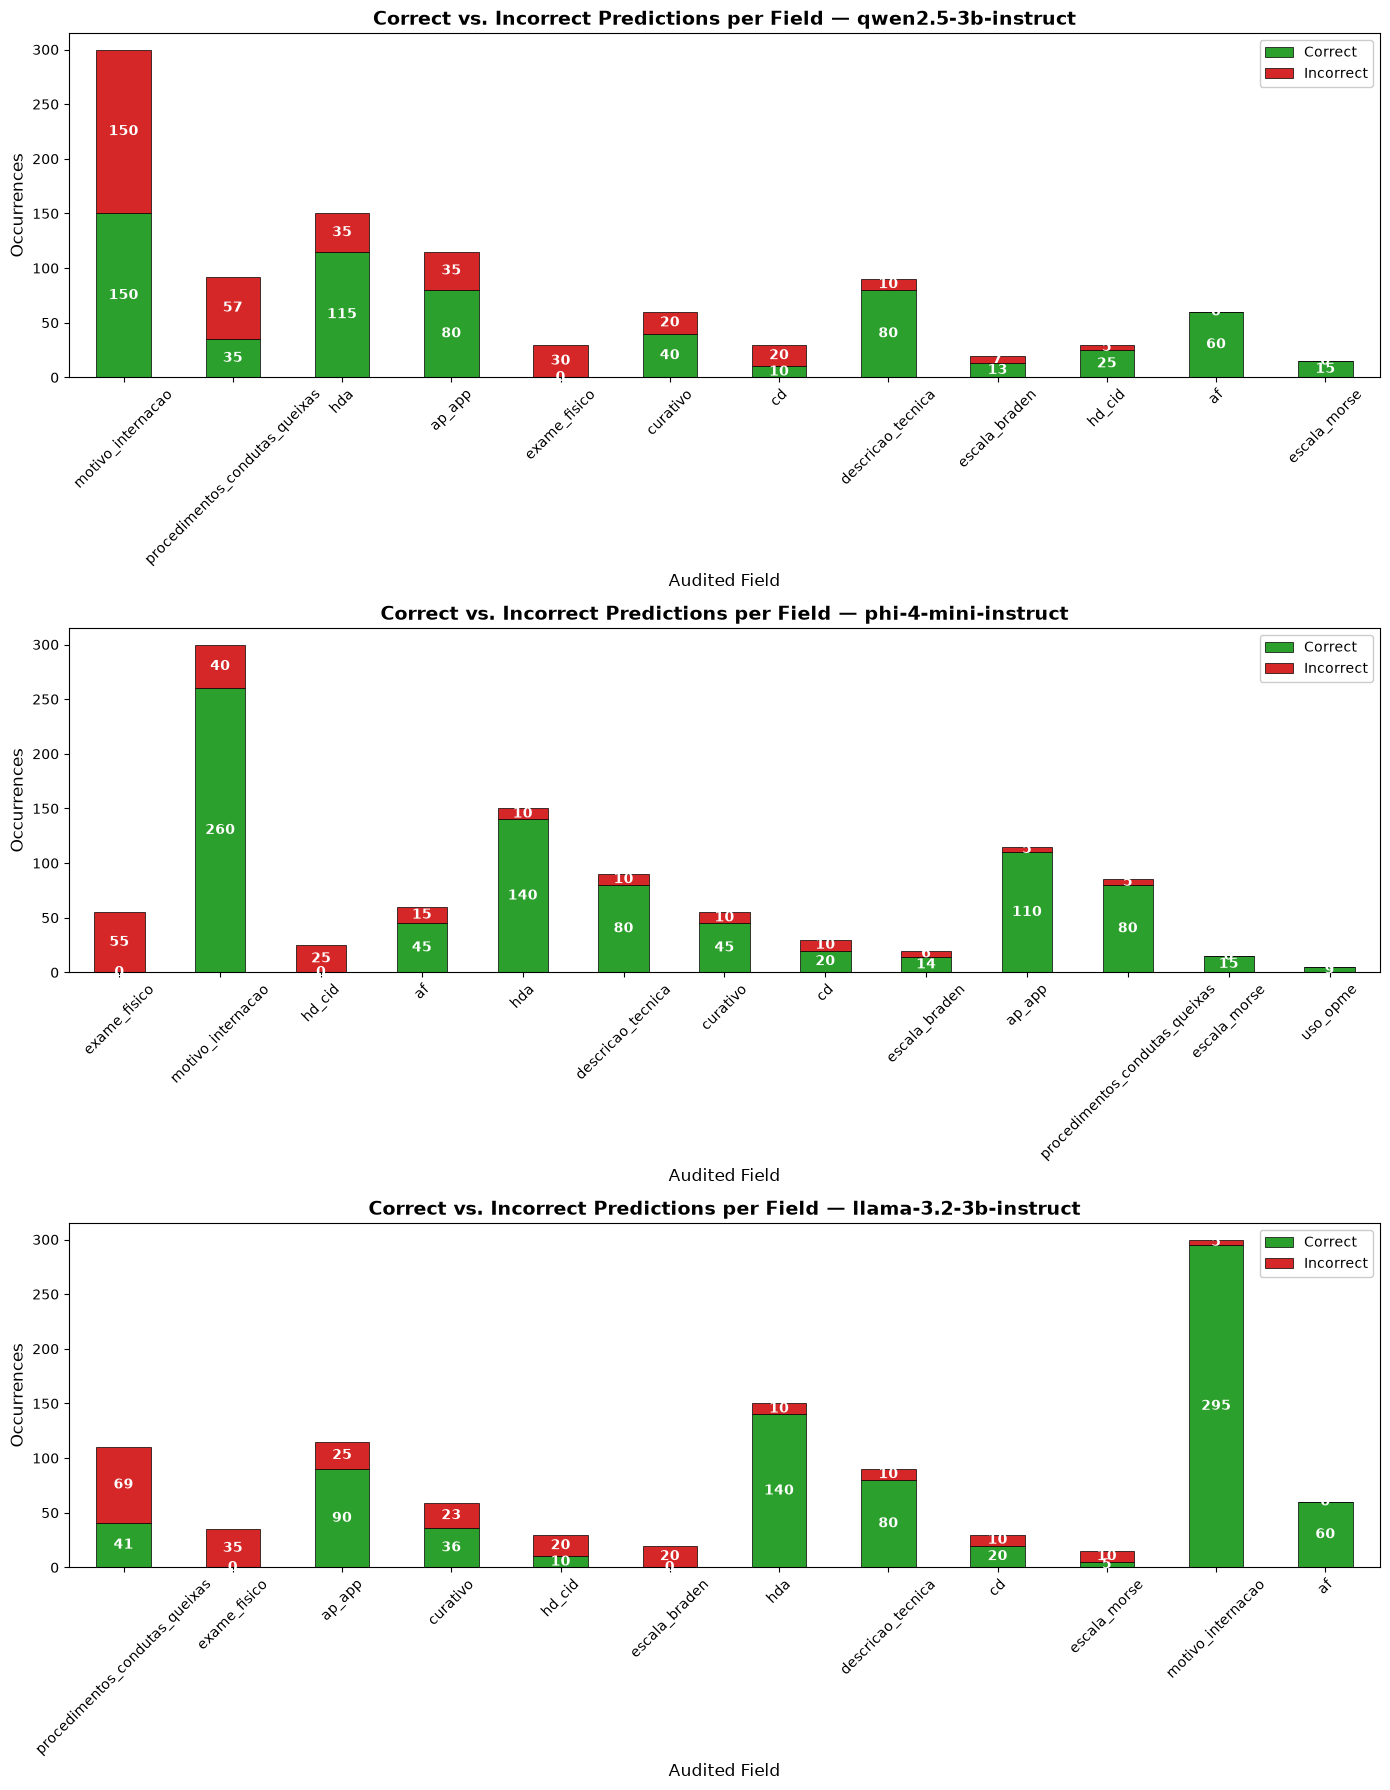

In [14]:
df_plot = df_metrics.copy()
df_plot['field'] = df_plot['field'].replace({'condutas': 'procedimentos_condutas_queixas'})

valid_fields = ground_truth['field'].unique().tolist()
df_plot = df_plot[df_plot['field'].isin(valid_fields)]

df_plot['correct'] = df_plot['expected'] == df_plot['normalized_classification']

df_hits = df_plot.groupby(['model', 'field'])['correct'].value_counts().unstack(fill_value=0).reset_index()

if True not in df_hits.columns: df_hits[True] = 0
if False not in df_hits.columns: df_hits[False] = 0
df_hits.rename(columns={True: 'Correct', False: 'Incorrect'}, inplace=True)

fig, axes = plt.subplots(len(ALL_MODELS), 1, figsize=(14, 6 * len(ALL_MODELS)))
if len(ALL_MODELS) == 1: axes = [axes]

for i, model in enumerate(ALL_MODELS):
    subset = df_hits[df_hits['model'] == model].set_index('field')
    subset = subset.sort_values(by=['Incorrect', 'Correct'], ascending=[False, False])

    subset[['Correct', 'Incorrect']].plot(
        kind='bar', stacked=True, color=['#2ca02c', '#d62728'],
        ax=axes[i], edgecolor='black', linewidth=0.5
    )

    axes[i].set_title(f"Correct vs. Incorrect Predictions per Field — {model}", fontsize=14, fontweight='bold')
    axes[i].set_ylabel("Occurrences", fontsize=12)
    axes[i].set_xlabel("Audited Field", fontsize=12)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend(loc='upper right', framealpha=1)

    for container in axes[i].containers:
        axes[i].bar_label(container, label_type='center', color='white', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


### 8.2 Matrizes de confusão por modelo

Duas visões das mesmas previsões. A **binária** (conforme × não conforme) é o que o auditor enxerga. A de **três classes** (conforme × incompleto × ausente) serve só para validar o modelo: uma não conformidade pode vir de um campo *incompleto* (a IA achou e julgou assim) ou *ausente* (a IA não achou), e a segunda matriz mostra se o modelo acertou o *tipo* de falha, e não só que houve uma.

O backend só conhece "conforme" e "não conforme". O gabarito ainda separa `ausente` de `incompleta`, mas aqui as duas significam "não conforme": a distinção é mantida apenas para medir o quanto cada modelo pega cada tipo de falha.

As tabelas abaixo das matrizes contam, por tipo de falha esperada, quantas foram sinalizadas de algum modo (`flagged`: o modelo disse "não conforme") e quantas com o tipo certo (`right_kind`). Também mostram as linhas por classe na amostra, para que uma taxa calculada sobre 1 ou 2 linhas não seja lida como mais do que é.


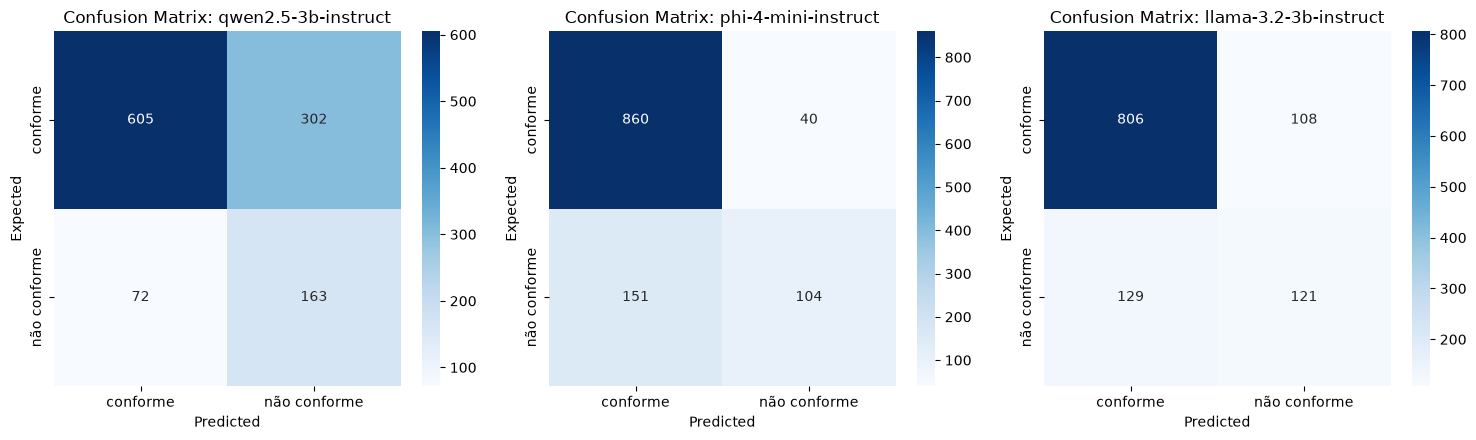

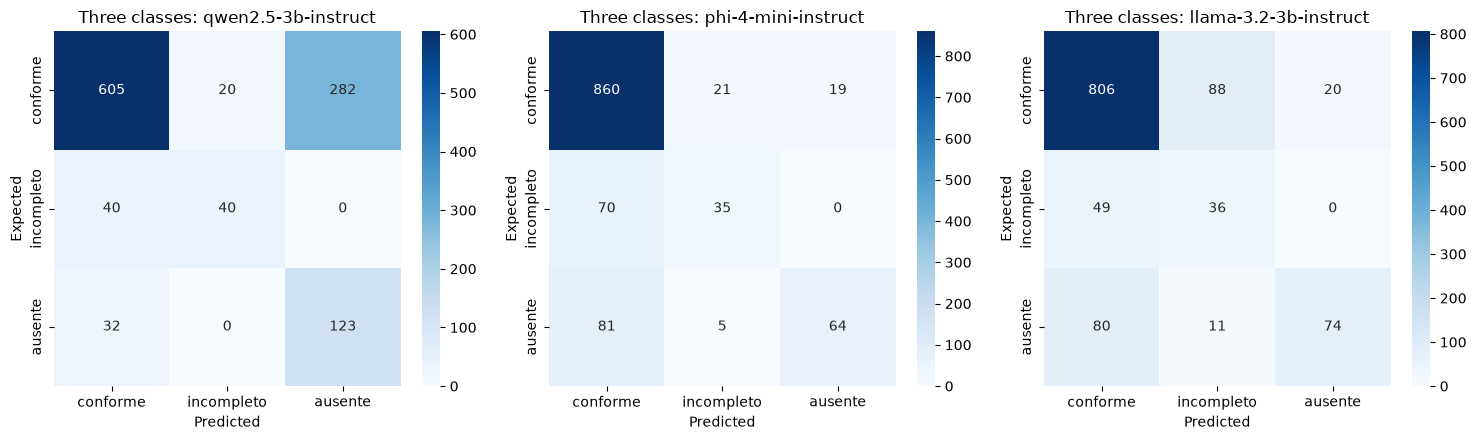

,model,expected_class,total,flagged,right_kind,flagged_rate,right_kind_rate
0,llama-3.2-3b-instruct,ausente,165,85,74,0.515,0.448
1,llama-3.2-3b-instruct,incompleto,85,36,36,0.424,0.424
2,phi-4-mini-instruct,ausente,150,69,64,0.460,0.427
3,phi-4-mini-instruct,incompleto,105,35,35,0.333,0.333
4,qwen2.5-3b-instruct,ausente,155,123,123,0.794,0.794
5,qwen2.5-3b-instruct,incompleto,80,40,40,0.500,0.500


Rows per expected class and model:


expected_class,conforme,incompleto,ausente
model,,,
llama-3.2-3b-instruct,914,85,165
phi-4-mini-instruct,900,105,150
qwen2.5-3b-instruct,907,80,155


In [15]:
labels_bin = ['conforme', 'não conforme']
to_label = {'present': 'conforme', 'absent': 'não conforme'}

df_metrics['expected_binary'] = df_metrics['expected'].map(to_label)
df_metrics['predicted_binary'] = df_metrics['normalized_classification'].map(to_label)

fig, axes = plt.subplots(1, len(ALL_MODELS), figsize=(5 * len(ALL_MODELS), 4.5))
if len(ALL_MODELS) == 1:
    axes = [axes]

for i, model in enumerate(ALL_MODELS):
    subset = df_metrics[df_metrics['model'] == model]
    if len(subset) == 0:
        continue

    cm = confusion_matrix(subset['expected_binary'], subset['predicted_binary'], labels=labels_bin)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=labels_bin, yticklabels=labels_bin)
    axes[i].set_title(f"Confusion Matrix: {model}")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Expected")

plt.tight_layout()
plt.show()

labels_cls = ['conforme', 'incompleto', 'ausente']

fig, axes = plt.subplots(1, len(ALL_MODELS), figsize=(5 * len(ALL_MODELS), 4.5))
if len(ALL_MODELS) == 1:
    axes = [axes]

for i, model in enumerate(ALL_MODELS):
    subset = df_metrics[df_metrics['model'] == model]
    if len(subset) == 0:
        continue

    cm = confusion_matrix(subset['expected_class'], subset['predicted_class'], labels=labels_cls)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=labels_cls, yticklabels=labels_cls)
    axes[i].set_title(f"Three classes: {model}")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Expected")

plt.tight_layout()
plt.show()

failures = df_metrics[df_metrics['expected_class'] != 'conforme'].copy()
failures['flagged'] = failures['predicted_class'] != 'conforme'
failures['right_kind'] = failures['predicted_class'] == failures['expected_class']
detection = (failures.groupby(['model', 'expected_class'])
             .agg(total=('flagged', 'count'), flagged=('flagged', 'sum'), right_kind=('right_kind', 'sum'))
             .reset_index())
detection['flagged_rate'] = (detection['flagged'] / detection['total']).round(3)
detection['right_kind_rate'] = (detection['right_kind'] / detection['total']).round(3)
display(detection)

print("Rows per expected class and model:")
display(pd.crosstab(df_metrics['model'], df_metrics['expected_class']).reindex(columns=labels_cls, fill_value=0))


## 9. Métricas de latência

O tempo é medido por chamada ao endpoint (todos os campos daquele prontuário)

In [16]:
df_times = df_raw.drop_duplicates(subset=['model', 'repetition', 'record'])[
    ['model', 'record', 'time_seconds']
]

latency_summary = df_times.groupby('model')['time_seconds'].agg(
    mean='mean', std='std', min='min', max='max'
).reset_index()

latency_summary.to_csv(RESULTS_DIR / 'latency_metrics.csv', index=False)
latency_summary


,model,mean,std,min,max
0,llama-3.2-3b-instruct,15.066626,0.590062,14.318797,15.845591
1,phi-4-mini-instruct,19.411924,0.612184,18.838302,20.380490
2,qwen2.5-3b-instruct,11.629379,3.424386,9.421749,18.425075


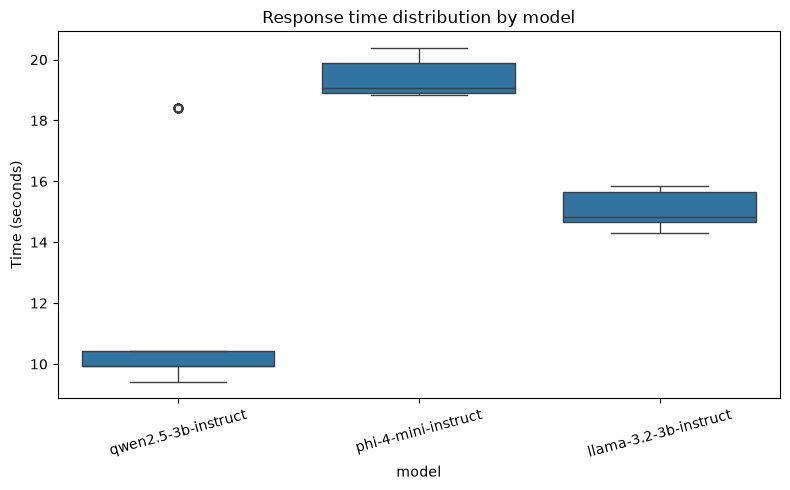

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_times, x='model', y='time_seconds')
plt.title('Response time distribution by model')
plt.ylabel('Time (seconds)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'latency_boxplot.png', dpi=150)
plt.show()


## 10. Retentativas e falhas de formato por modelo

Aqui as duas espécies de falha são medidas em separado, cada uma com o seu significado:

- **Infraestrutura** (`timeout`, `http_error`): uma falha que se repete interrompe a execução, então o que chega até aqui é só o que o backend superou repetindo a chamada (ele tenta até 3 vezes). `retry_rate_pct` é a parcela das tentativas à IA que precisou ser repetida: mostra o quanto o ambiente oscilou sem invalidar a rodada, e não é uma característica do modelo.
- **Formato do modelo** (`invalid_json`, `campos_ausentes`, `empty_response`): o modelo respondeu fora do formato pedido, o que é resultado sobre ele. `format_error_rate_pct` é a parcela dos campos enviados que ficaram sem resposta por esse motivo. Com `AI_JSON_SCHEMA=1` ela tende a 0, porque o servidor só deixa o modelo emitir o formato pedido; com `AI_JSON_SCHEMA=0` ela mede o quanto cada modelo consegue escrever o JSON pedido.

Os números saem da assinatura `_ia_meta` de cada job, lida do `ia_meta.csv`, que acumula as rodadas de todos os modelos. Compare apenas rodadas feitas no mesmo modo (coluna `json_schema`).


In [18]:
df_meta_all = pd.read_csv(RESULTS_DIR / 'ia_meta.csv')

retry_and_format_df = df_meta_all.groupby('model').agg(
    total_calls=('ia_calls', 'sum'),
    total_attempts=('ia_attempts', 'sum'),
    fields_sent=('fields_sent', 'sum'),
    fields_error=('fields_error', 'sum'),
).reset_index()

retry_and_format_df['retries'] = retry_and_format_df['total_attempts'] - retry_and_format_df['total_calls']
retry_and_format_df['retry_rate_pct'] = (retry_and_format_df['retries'] / retry_and_format_df['total_attempts'] * 100).round(2)
retry_and_format_df['format_error_rate_pct'] = (retry_and_format_df['fields_error'] / retry_and_format_df['fields_sent'] * 100).round(2)
retry_and_format_df

,model,total_calls,total_attempts,fields_sent,fields_error,retries,retry_rate_pct,format_error_rate_pct
0,llama-3.2-3b-instruct,1060,1060,1870,0,0,0.0,0.0
1,phi-4-mini-instruct,1060,1060,1870,0,0,0.0,0.0
2,qwen2.5-3b-instruct,1060,1060,1870,0,0,0.0,0.0


## 11. Tabela final consolidada

In [ ]:
final_summary = df_quality_summary.merge(latency_summary, on='model').merge(
    retry_and_format_df[['model', 'retry_rate_pct', 'format_error_rate_pct']], on='model'
)
final_summary = final_summary.round(3)
final_summary.to_csv(RESULTS_DIR / 'final_summary.csv', index=False)
final_summary


,model,n_samples,precision (Qualidade),recall (Qualidade),f1 (Qualidade),precision (Presença),recall (Presença),f1 (Presença),mean,std,min,max,retry_rate_pct,format_error_rate_pct
0,qwen2.5-3b-instruct,1142,0.894,0.667,0.764,0.953,0.678,0.792,11.629,3.424,9.422,18.425,0.0,0.0
1,phi-4-mini-instruct,1155,0.851,0.956,0.900,0.915,0.954,0.934,19.412,0.612,18.838,20.380,0.0,0.0
2,llama-3.2-3b-instruct,1164,0.862,0.882,0.872,0.910,0.883,0.896,15.067,0.590,14.319,15.846,0.0,0.0


## Conclusão
